# State-Wise Annual Rainfall Analysis and Prediction in India Using Machine Learning
**Author:** Civil Engineering Undergraduate Student  
**Discipline:** Water Resources Engineering & Hydrology  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, ipywidgets

---

## Project Overview
This project investigates the historical patterns and future predictability of state-wise annual rainfall across India over 115 years (1901–2015) using observational data from the **India Meteorological Department (IMD)**.

### Central Research Question:
> *"Can historical rainfall data be used to estimate the annual rainfall of an Indian state in a future year using basic Machine Learning algorithms?"*

### Project Workflow
1. **Phase 1:** Data Collection, Inspection, and Hydrological Understanding
2. **Phase 2:** Data Cleaning and State-Wise Preprocessing
3. **Phase 3:** Exploratory Data Analysis (5 Hydrological Visualizations)
4. **Phase 4:** Machine Learning (Baseline, Linear Regression, Decision Tree, Random Forest)
5. **Phase 5:** Model Comparison and Performance Evaluation (MAE, MSE, RMSE, R²)
6. **Phase 6:** Interactive Rainfall Prediction System (`ipywidgets`)


---
## Phase 1: Data Collection and Inspection

In hydrology, a **Rainfall Normal** is the 30-year or 50-year mathematical average of rainfall recorded over a fixed benchmark period (e.g., 1951–2000). 
- `district wise rainfall normal.csv` contains static normals for 641 districts. Because it has **no `YEAR` column**, it cannot be used alone to predict future years.
- Therefore, we also load the official 115-year historical time-series dataset: `rainfall in india 1901-2015.csv` (IMD).


In [1]:
# ==============================================================================
# PHASE 1: DATA COLLECTION, INSPECTION, AND UNDERSTANDING
# ==============================================================================

import pandas as pd
import numpy as np

# 1. Load the District Normals Dataset
file_path_normals = 'data/district wise rainfall normal.csv'
df_normals = pd.read_csv(file_path_normals)

# 2. Load the IMD 115-Year Historical Time-Series Dataset
file_path_historical = 'data/rainfall in india 1901-2015.csv'
df_historical = pd.read_csv(file_path_historical)

print("=" * 70)
print("1. INSPECTING DISTRICT-WISE RAINFALL NORMALS DATASET")
print("=" * 70)
print(f"Shape: {df_normals.shape[0]} rows, {df_normals.shape[1]} columns")
print(f"Missing Values: {df_normals.isnull().sum().sum()}")
display(df_normals[['STATE_UT_NAME', 'DISTRICT', 'ANNUAL', 'Jun-Sep']].head(3))

print("\n" + "=" * 70)
print("2. INSPECTING 115-YEAR HISTORICAL TIME-SERIES DATASET (IMD)")
print("=" * 70)
print(f"Shape: {df_historical.shape[0]} rows, {df_historical.shape[1]} columns")
print(f"Time Horizon: {df_historical['YEAR'].min()} to {df_historical['YEAR'].max()} ({df_historical['YEAR'].nunique()} continuous years)")
print(f"Number of Meteorological Subdivisions: {df_historical['SUBDIVISION'].nunique()}")
display(df_historical[['SUBDIVISION', 'YEAR', 'ANNUAL', 'Jun-Sep']].head(3))


1. INSPECTING DISTRICT-WISE RAINFALL NORMALS DATASET
Shape: 641 rows, 19 columns
Missing Values: 0


,STATE_UT_NAME,DISTRICT,ANNUAL,Jun-Sep
0,ANDAMAN And NICOBAR ISLANDS,NICOBAR,2805.2,1207.2
1,ANDAMAN And NICOBAR ISLANDS,SOUTH ANDAMAN,3015.7,1757.2
2,ANDAMAN And NICOBAR ISLANDS,N & M ANDAMAN,2913.3,1884.4



2. INSPECTING 115-YEAR HISTORICAL TIME-SERIES DATASET (IMD)
Shape: 4116 rows, 19 columns
Time Horizon: 1901 to 2015 (115 continuous years)
Number of Meteorological Subdivisions: 36


,SUBDIVISION,YEAR,ANNUAL,Jun-Sep
0,ANDAMAN & NICOBAR ISLANDS,1901,3373.2,1696.3
1,ANDAMAN & NICOBAR ISLANDS,1902,3520.7,2185.9
2,ANDAMAN & NICOBAR ISLANDS,1903,2957.4,1874.0


---
## Phase 2: Data Cleaning and Structuring

### Hydrological Data Cleaning Principles:
1. **Subdivision-Wise Monthly Median Imputation:** Missing monthly records are filled using the median rainfall of that specific meteorological subdivision.
2. **Exact Mathematical Sum:** Annual rainfall is recalculated as $\text{ANNUAL} = \sum_{m=\text{JAN}}^{\text{DEC}} \text{Rainfall}_m$.
3. **State Mapping:** The 36 IMD subdivisions are mapped to governing Indian States, and aggregated using `groupby(['STATE', 'YEAR']).mean()`.


In [2]:
# ==============================================================================
# PHASE 2: DATA CLEANING AND STRUCTURING
# ==============================================================================

df_clean = df_historical.copy()
months = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 
          'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']

# Step 1: Impute missing monthly values using subdivision median
for month in months:
    df_clean[month] = df_clean.groupby('SUBDIVISION')[month].transform(
        lambda s: s.fillna(s.median())
    )

# Step 2: Recalculate annual and seasonal totals accurately
df_clean['ANNUAL'] = df_clean[months].sum(axis=1)
df_clean['Jan-Feb'] = df_clean['JAN'] + df_clean['FEB']
df_clean['Mar-May'] = df_clean['MAR'] + df_clean['APR'] + df_clean['MAY']
df_clean['Jun-Sep'] = df_clean['JUN'] + df_clean['JUL'] + df_clean['AUG'] + df_clean['SEP']
df_clean['Oct-Dec'] = df_clean['OCT'] + df_clean['NOV'] + df_clean['DEC']

# Step 3: Map 36 IMD Subdivisions to Indian States
subdivision_to_state = {
    'ANDAMAN & NICOBAR ISLANDS': 'Andaman & Nicobar Islands',
    'ARUNACHAL PRADESH': 'Arunachal Pradesh',
    'ASSAM & MEGHALAYA': 'Assam & Meghalaya',
    'NAGA MANI MIZO TRIPURA': 'Northeastern States (Nagaland, Manipur, Mizoram, Tripura)',
    'SUB HIMALAYAN WEST BENGAL & SIKKIM': 'West Bengal & Sikkim',
    'GANGETIC WEST BENGAL': 'West Bengal',
    'ORISSA': 'Odisha',
    'JHARKHAND': 'Jharkhand',
    'BIHAR': 'Bihar',
    'EAST UTTAR PRADESH': 'Uttar Pradesh',
    'WEST UTTAR PRADESH': 'Uttar Pradesh',
    'UTTARAKHAND': 'Uttarakhand',
    'HARYANA DELHI & CHANDIGARH': 'Haryana & Delhi',
    'PUNJAB': 'Punjab',
    'HIMACHAL PRADESH': 'Himachal Pradesh',
    'JAMMU & KASHMIR': 'Jammu & Kashmir',
    'WEST RAJASTHAN': 'Rajasthan',
    'EAST RAJASTHAN': 'Rajasthan',
    'WEST MADHYA PRADESH': 'Madhya Pradesh',
    'EAST MADHYA PRADESH': 'Madhya Pradesh',
    'GUJARAT REGION': 'Gujarat',
    'SAURASHTRA & KUTCH': 'Gujarat',
    'KONKAN & GOA': 'Goa & Konkan',
    'MADHYA MAHARASHTRA': 'Maharashtra',
    'MATATHWADA': 'Maharashtra',
    'VIDARBHA': 'Maharashtra',
    'CHHATTISGARH': 'Chhattisgarh',
    'COASTAL ANDHRA PRADESH': 'Andhra Pradesh',
    'TELANGANA': 'Telangana',
    'RAYALSEEMA': 'Andhra Pradesh',
    'TAMIL NADU': 'Tamil Nadu',
    'COASTAL KARNATAKA': 'Karnataka',
    'NORTH INTERIOR KARNATAKA': 'Karnataka',
    'SOUTH INTERIOR KARNATAKA': 'Karnataka',
    'KERALA': 'Kerala',
    'LAKSHADWEEP': 'Lakshadweep'
}

df_clean['STATE'] = df_clean['SUBDIVISION'].map(subdivision_to_state)

# Step 4: Aggregate to State-Wise Annual Records
df_state = df_clean.groupby(['STATE', 'YEAR'])['ANNUAL'].mean().reset_index()
df_state['ANNUAL'] = df_state['ANNUAL'].round(1)

# Save cleaned files
df_clean.to_csv('data/cleaned_historical_rainfall.csv', index=False)
df_state.to_csv('data/cleaned_state_wise_rainfall.csv', index=False)

print(f"Total remaining missing values: {df_clean.isnull().sum().sum()}")
print(f"Number of unique States / Regions: {df_state['STATE'].nunique()}")
display(df_state.head(5))


Total remaining missing values: 0
Number of unique States / Regions: 27


,STATE,YEAR,ANNUAL
0,Andaman & Nicobar Islands,1901,3373.2
1,Andaman & Nicobar Islands,1902,3520.7
2,Andaman & Nicobar Islands,1903,2957.4
3,Andaman & Nicobar Islands,1904,3079.6
4,Andaman & Nicobar Islands,1905,2566.7


---
## Phase 3: Exploratory Data Analysis (EDA)

Here we generate 5 meaningful hydrological visualizations:
1. **State-Wise Average Annual Rainfall** (Spatial variation across India).
2. **Year-Wise Rainfall Trend (1901–2015)** (Historic flood of 1961 and severe drought of 2009).
3. **Multi-State Comparison** (Contrasting humid coastal vs. semi-arid regions).
4. **Top 5 Wettest vs. Top 5 Driest States** (The 7x hydrological contrast).
5. **Monthly Rainfall Heatmap** (Monsoon concentration from June to September).


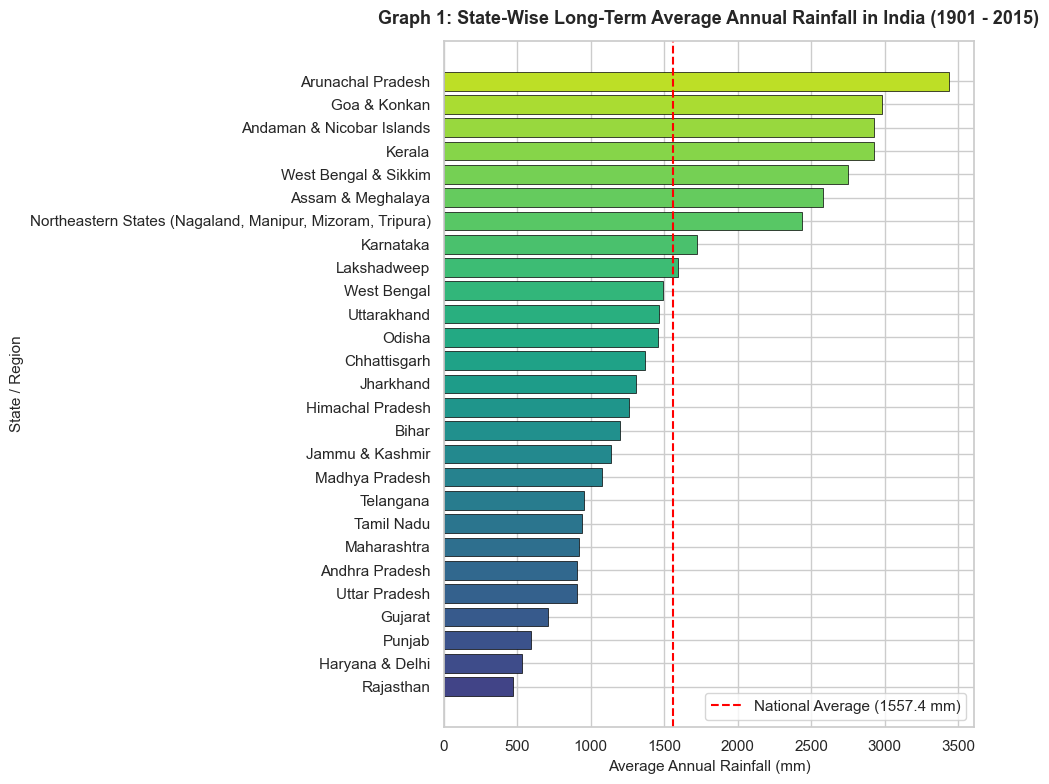

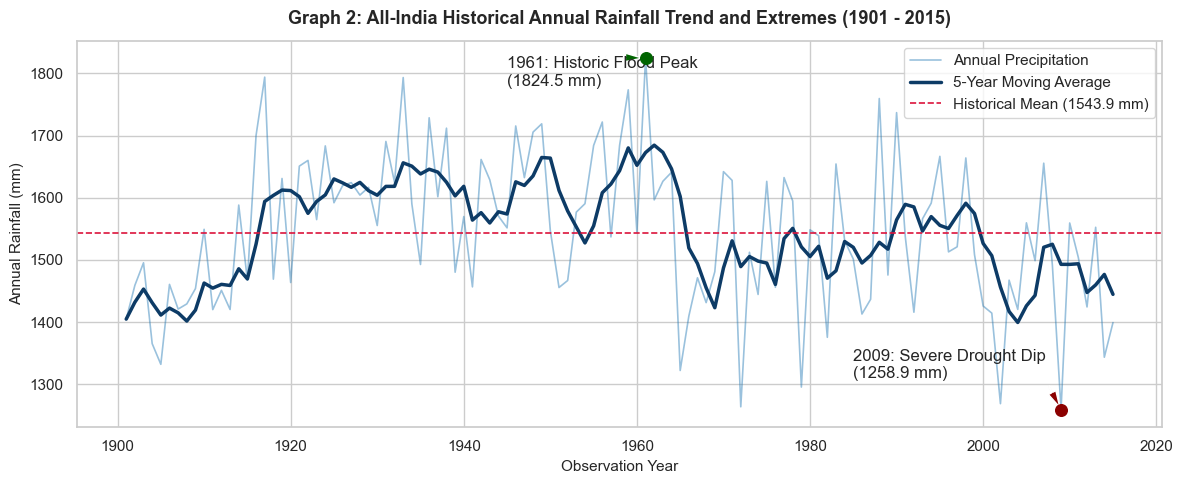

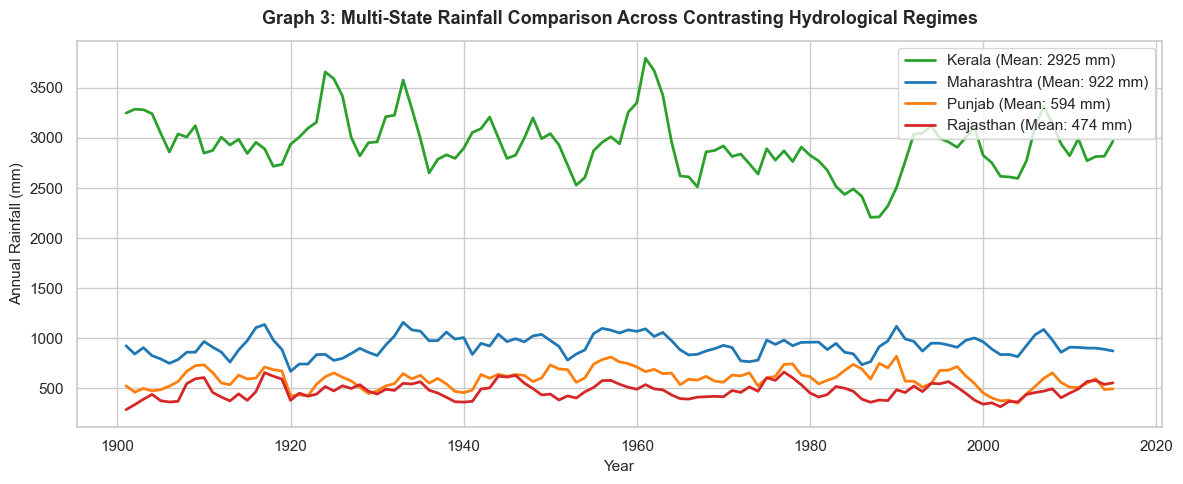

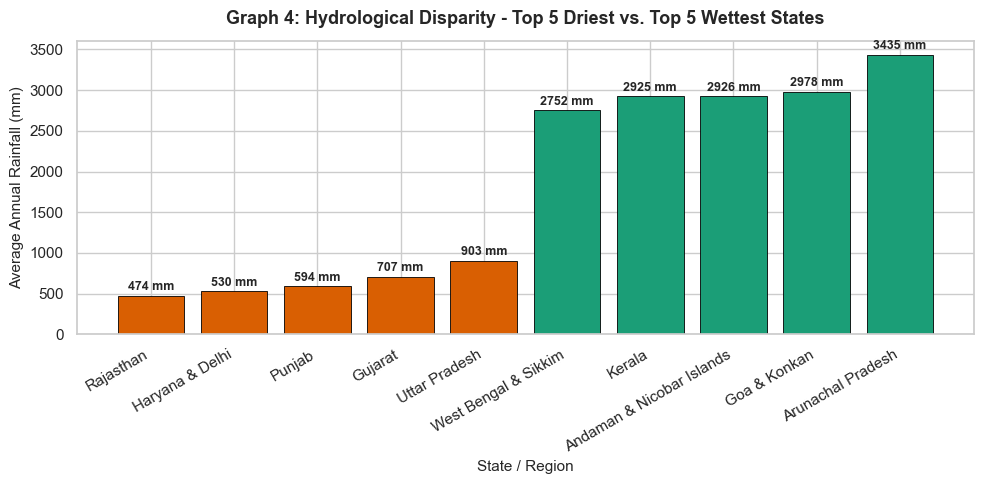

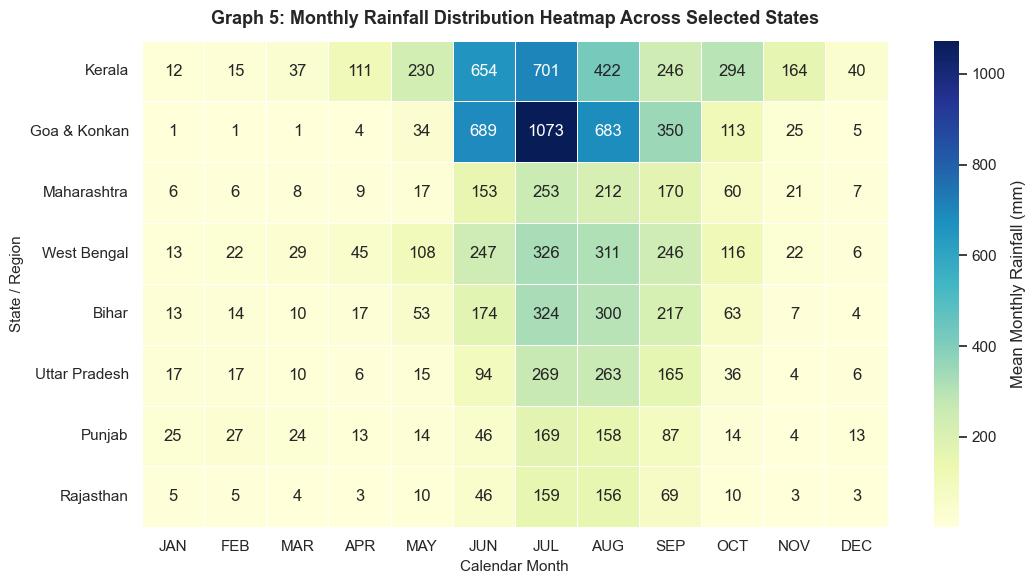

In [3]:
# ==============================================================================
# PHASE 3: EXPLORATORY DATA ANALYSIS (5 HYDROLOGICAL PLOTS)
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'

# 1. State-Wise Average Annual Rainfall
plt.figure(figsize=(10, 8))
state_means = df_state.groupby('STATE')['ANNUAL'].mean().sort_values(ascending=True)
colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(state_means)))
plt.barh(state_means.index, state_means.values, color=colors, edgecolor='black', linewidth=0.5)
plt.axvline(state_means.mean(), color='red', linestyle='--', linewidth=1.5, label=f'National Average ({state_means.mean():.1f} mm)')
plt.title('Graph 1: State-Wise Long-Term Average Annual Rainfall in India (1901 - 2015)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Average Annual Rainfall (mm)', fontsize=11)
plt.ylabel('State / Region', fontsize=11)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 2. Year-Wise Historical Rainfall Trend
plt.figure(figsize=(12, 5))
nat_trend = df_state.groupby('YEAR')['ANNUAL'].mean().reset_index()
nat_trend['5yr_MA'] = nat_trend['ANNUAL'].rolling(window=5, min_periods=1).mean()

plt.plot(nat_trend['YEAR'], nat_trend['ANNUAL'], color='#1f77b4', alpha=0.45, linewidth=1.2, label='Annual Precipitation')
plt.plot(nat_trend['YEAR'], nat_trend['5yr_MA'], color='#0d3b66', linewidth=2.5, label='5-Year Moving Average')
plt.axhline(nat_trend['ANNUAL'].mean(), color='crimson', linestyle='--', linewidth=1.2, label=f'Historical Mean ({nat_trend["ANNUAL"].mean():.1f} mm)')
plt.scatter([1961], [1824.5], color='darkgreen', s=70, zorder=5)
plt.annotate('1961: Historic Flood Peak\n(1824.5 mm)', (1961, 1824.5), xytext=(1945, 1780),
             arrowprops=dict(facecolor='darkgreen', shrink=0.08, width=1, headwidth=6))
plt.scatter([2009], [1258.9], color='darkred', s=70, zorder=5)
plt.annotate('2009: Severe Drought Dip\n(1258.9 mm)', (2009, 1258.9), xytext=(1985, 1310),
             arrowprops=dict(facecolor='darkred', shrink=0.08, width=1, headwidth=6))
plt.title('Graph 2: All-India Historical Annual Rainfall Trend and Extremes (1901 - 2015)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Observation Year', fontsize=11)
plt.ylabel('Annual Rainfall (mm)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 3. Multi-State Comparison
plt.figure(figsize=(12, 5))
selected_states = ['Kerala', 'Maharashtra', 'Punjab', 'Rajasthan']
colors_dict = {'Kerala': '#2ca02c', 'Maharashtra': '#1f77b4', 'Punjab': '#ff7f0e', 'Rajasthan': '#d62728'}
for st in selected_states:
    sdata = df_state[df_state['STATE'] == st].sort_values('YEAR')
    plt.plot(sdata['YEAR'], sdata['ANNUAL'].rolling(3, min_periods=1).mean(), 
             label=f"{st} (Mean: {sdata['ANNUAL'].mean():.0f} mm)", color=colors_dict[st], linewidth=2)
plt.title('Graph 3: Multi-State Rainfall Comparison Across Contrasting Hydrological Regimes', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Year', fontsize=11)
plt.ylabel('Annual Rainfall (mm)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# 4. Top 5 Wettest vs Top 5 Driest States
plt.figure(figsize=(10, 5))
top5 = state_means.tail(5)
bot5 = state_means.head(5)
ext = pd.concat([bot5, top5])
bars = plt.bar(ext.index, ext.values, color=['#d95f02']*5 + ['#1b9e77']*5, edgecolor='black', linewidth=0.6)
plt.title('Graph 4: Hydrological Disparity - Top 5 Driest vs. Top 5 Wettest States', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('State / Region', fontsize=11)
plt.ylabel('Average Annual Rainfall (mm)', fontsize=11)
plt.xticks(rotation=30, ha='right')
for b in bars:
    h = b.get_height()
    plt.annotate(f'{h:.0f} mm', xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4), textcoords="offset points", ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

# 5. Monthly Rainfall Heatmap
plt.figure(figsize=(11, 6))
major_states = ['Kerala', 'Goa & Konkan', 'Maharashtra', 'West Bengal', 'Bihar', 'Uttar Pradesh', 'Punjab', 'Rajasthan']
monthly_matrix = df_clean[df_clean['STATE'].isin(major_states)].groupby('STATE')[months].mean().loc[major_states]
sns.heatmap(monthly_matrix, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws={'label': 'Mean Monthly Rainfall (mm)'}, linewidths=0.5)
plt.title('Graph 5: Monthly Rainfall Distribution Heatmap Across Selected States', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Calendar Month', fontsize=11)
plt.ylabel('State / Region', fontsize=11)
plt.tight_layout()
plt.show()


---
## Phase 4: Machine Learning (Regression Modeling)

### Machine Learning Setup:
- **Feature ($X$):** `YEAR`
- **Target ($y$):** `ANNUAL` (mm)
- **Train/Test Splitting:** Strict Chronological Split (Train: 1901–1992, Test: 1993–2015). **Never random shuffle.**
- **Models:**
  1. Historical Mean Baseline (Climatological Normal)
  2. Linear Regression (Trend line $y = mx + c$)
  3. Decision Tree Regressor (Piecewise constant step splits)
  4. Random Forest Regressor (Ensemble of 100 decorrelated trees)


In [4]:
# ==============================================================================
# PHASE 4: MACHINE LEARNING (TRAINING & EVALUATION)
# ==============================================================================

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_state = 'Maharashtra'
state_df = df_state[df_state['STATE'] == target_state].sort_values('YEAR').copy()

# Chronological Train-Test Split (80% Train: 1901-1992, 20% Test: 1993-2015)
split_idx = int(len(state_df) * 0.80)
train_data = state_df.iloc[:split_idx]
test_data = state_df.iloc[split_idx:]

X_train = train_data[['YEAR']].values
y_train = train_data['ANNUAL'].values
X_test = test_data[['YEAR']].values
y_test = test_data['ANNUAL'].values

# Model 1: Baseline
baseline_val = y_train.mean()
y_pred_baseline = np.full(len(y_test), baseline_val)

# Model 2: Linear Regression
lr = LinearRegression().fit(X_train, y_train)
y_pred_linear = lr.predict(X_test)

# Model 3: Decision Tree
dt = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_train)
y_pred_tree = dt.predict(X_test)

# Model 4: Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42).fit(X_train, y_train)
y_pred_forest = rf.predict(X_test)

# Evaluation
models_eval = {
    'Historical Mean Baseline': y_pred_baseline,
    'Linear Regression': y_pred_linear,
    'Decision Tree Regressor': y_pred_tree,
    'Random Forest Regressor': y_pred_forest
}

results = []
for name, preds in models_eval.items():
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    results.append({
        'Model': name,
        'MAE (mm)': round(mae, 2),
        'MSE (mm²)': round(mse, 2),
        'RMSE (mm)': round(rmse, 2),
        'R² Score': round(r2, 4)
    })

df_evaluation = pd.DataFrame(results)
print("EVALUATION METRICS TABLE ON UNSEEN TEST DATA (1993 - 2015):")
display(df_evaluation)


EVALUATION METRICS TABLE ON UNSEEN TEST DATA (1993 - 2015):


,Model,MAE (mm),MSE (mm²),RMSE (mm),R² Score
0,Historical Mean Baseline,114.52,17396.60,131.90,-0.0024
1,Linear Regression,121.16,19321.58,139.00,-0.1133
2,Decision Tree Regressor,140.59,24817.77,157.54,-0.4300
3,Random Forest Regressor,115.98,17667.22,132.92,-0.0180


---
## Phase 5: Model Comparison and Scientific Selection

We generate:
1. Error comparison bar chart (MAE vs. RMSE).
2. Actual vs. Predicted Time-Series tracking plot across the test horizon (1993–2015).


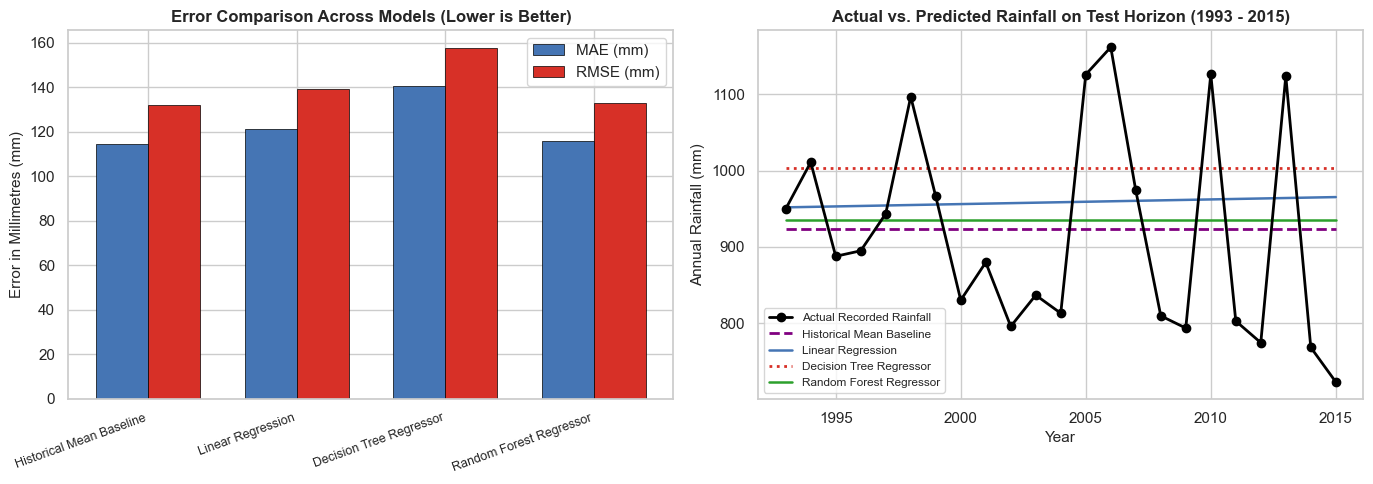

In [5]:
# ==============================================================================
# PHASE 5: MODEL COMPARISON VISUALIZATION
# ==============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Error Bar Chart
models = df_evaluation['Model'].tolist()
mae_vals = df_evaluation['MAE (mm)'].tolist()
rmse_vals = df_evaluation['RMSE (mm)'].tolist()
x = np.arange(len(models))
w = 0.35

axes[0].bar(x - w/2, mae_vals, w, label='MAE (mm)', color='#4575b4', edgecolor='black', linewidth=0.5)
axes[0].bar(x + w/2, rmse_vals, w, label='RMSE (mm)', color='#d73027', edgecolor='black', linewidth=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=20, ha='right', fontsize=9)
axes[0].set_ylabel('Error in Millimetres (mm)', fontsize=11)
axes[0].set_title('Error Comparison Across Models (Lower is Better)', fontsize=12, fontweight='bold')
axes[0].legend()

# Plot 2: Actual vs Predicted Time Series
test_yrs = test_data['YEAR'].values
axes[1].plot(test_yrs, y_test, label='Actual Recorded Rainfall', color='black', marker='o', linewidth=2, zorder=5)
axes[1].plot(test_yrs, y_pred_baseline, label='Historical Mean Baseline', color='purple', linestyle='--', linewidth=2)
axes[1].plot(test_yrs, y_pred_linear, label='Linear Regression', color='#4575b4', linewidth=1.8)
axes[1].plot(test_yrs, y_pred_tree, label='Decision Tree Regressor', color='#d73027', linestyle=':', linewidth=2)
axes[1].plot(test_yrs, y_pred_forest, label='Random Forest Regressor', color='#2ca02c', linewidth=1.8)

axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Annual Rainfall (mm)', fontsize=11)
axes[1].set_title('Actual vs. Predicted Rainfall on Test Horizon (1993 - 2015)', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Phase 6: Interactive Rainfall Prediction System (`ipywidgets`)

Select any Indian State, a forecast year, and an ML model to generate:
- The predicted rainfall in millimetres (mm).
- The statistically expected fluctuation range ($\pm 1\sigma$).
- A full historical time-series graph with the predicted point clearly marked.
- Automated extrapolation warning if predicting $>10$ years into the future.


In [6]:
# ==============================================================================
# PHASE 6: INTERACTIVE PREDICTION SYSTEM (ipywidgets)
# ==============================================================================

import ipywidgets as widgets
from IPython.display import display, clear_output

state_dropdown = widgets.Dropdown(
    options=sorted(df_state['STATE'].unique().tolist()),
    value='Maharashtra',
    description='State/UT:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='380px')
)

year_input = widgets.BoundedIntText(
    value=2020,
    min=1901,
    max=2050,
    step=1,
    description='Forecast Year:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='380px')
)

model_dropdown = widgets.Dropdown(
    options=[
        'Historical Mean Baseline',
        'Linear Regression',
        'Decision Tree Regressor',
        'Random Forest Regressor'
    ],
    value='Random Forest Regressor',
    description='ML Model:',
    style={'description_width': '120px'},
    layout=widgets.Layout(width='380px')
)

predict_button = widgets.Button(
    description='Predict Annual Rainfall',
    button_style='primary',
    icon='cloud',
    layout=widgets.Layout(width='240px', height='40px', margin='10px 0 0 120px')
)

output_area = widgets.Output()

def on_predict_button_clicked(b):
    with output_area:
        clear_output()
        sel_state = state_dropdown.value
        tgt_year = year_input.value
        sel_model = model_dropdown.value
        
        s_data = df_state[df_state['STATE'] == sel_state].sort_values('YEAR').copy()
        if len(s_data) < 30:
            print(f"❌ Error: {sel_state} has insufficient observations (<30 records).")
            return
            
        X_all = s_data[['YEAR']].values
        y_all = s_data['ANNUAL'].values
        h_mean = y_all.mean()
        h_std = y_all.std()
        
        if sel_model == 'Historical Mean Baseline':
            pred = h_mean
            note = "Uses long-term arithmetic mean (IMD Climatological Normal)."
        elif sel_model == 'Linear Regression':
            m = LinearRegression().fit(X_all, y_all)
            pred = float(m.predict([[tgt_year]])[0])
            note = f"Linear trend line (Slope: {m.coef_[0]:.2f} mm/year)."
        elif sel_model == 'Decision Tree Regressor':
            m = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_all, y_all)
            pred = float(m.predict([[tgt_year]])[0])
            note = "Step-wise decision tree leaves."
        elif sel_model == 'Random Forest Regressor':
            m = RandomForestRegressor(n_estimators=100, max_depth=3, random_state=42).fit(X_all, y_all)
            pred = float(m.predict([[tgt_year]])[0])
            note = "Ensemble average of 100 decorrelated decision trees."
            
        pred = max(0.0, round(pred, 1))
        low_b = max(0.0, round(pred - h_std, 1))
        high_b = round(pred + h_std, 1)
        
        print("=" * 75)
        print(f" HYDROLOGICAL FORECAST REPORT: {sel_state.upper()} ({tgt_year})")
        print("=" * 75)
        print(f"• Algorithm Selected:        {sel_model}")
        print(f"• Forecast Target Year:      {tgt_year}")
        print(f"• Predicted Annual Rainfall: {pred:.1f} mm")
        print(f"• Expected Fluctuation Range (±1σ): {low_b:.1f} mm to {high_b:.1f} mm")
        print(f"• State Long-Term Normal:    {h_mean:.1f} mm (Std Dev: ±{h_std:.1f} mm)")
        
        if tgt_year > 2025:
            print("\n⚠️  ENGINEERING EXTRAPOLATION WARNING:")
            print(f"   Target year {tgt_year} is >10 years beyond observation baseline (2015).")
            print("   Statistical regression algorithms cannot forecast long-term climate change shifts.")
            print("   For 30-to-50 year dam planning, coupled Global Circulation Models (GCMs) must be utilized.")
            
        print(f"\n• Hydrological Note: {note}")
        print("-" * 75)
        
        fig, ax = plt.subplots(figsize=(11, 4.5))
        ax.plot(s_data['YEAR'], s_data['ANNUAL'], color='#1f77b4', marker='o', markersize=3, alpha=0.6, label='Recorded Rainfall')
        ax.axhline(h_mean, color='green', linestyle='--', linewidth=1.5, label=f'Historical Normal ({h_mean:.0f} mm)')
        ax.scatter([tgt_year], [pred], color='crimson', s=120, zorder=6, edgecolor='black', label=f'Forecast ({pred:.0f} mm)')
        ax.errorbar([tgt_year], [pred], yerr=[[pred - low_b], [high_b - pred]], fmt='none', ecolor='crimson', elinewidth=2, capsize=6, capthick=2, label='Expected Range (±1σ)')
        ax.set_title(f"Historical Rainfall and {tgt_year} Forecast for {sel_state}", fontsize=12, fontweight='bold')
        ax.set_xlabel("Year")
        ax.set_ylabel("Annual Rainfall (mm)")
        ax.legend(loc='upper right')
        plt.tight_layout()
        plt.show()

predict_button.on_click(on_predict_button_clicked)

ui_container = widgets.VBox([
    widgets.HTML("<h3>🌧️ State-Wise Annual Rainfall Prediction System</h3>"),
    widgets.HTML("<p>Select an Indian State, enter a forecast year, choose an ML model, and click Predict:</p>"),
    state_dropdown,
    year_input,
    model_dropdown,
    predict_button,
    widgets.HTML("<hr>"),
    output_area
])

display(ui_container)
